# 02 - Feature Engineering

This notebook converts raw used car listing data into model-ready features. It focuses on reusable transformations that can be applied consistently during training, API inference, and Streamlit prediction.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_preprocessing import (
    clean_data,
    create_processed_dataset,
    identify_feature_groups,
    build_preprocessor,
)
from src.feature_engineering import engineer_features, get_model_feature_columns
from src.utils import PROCESSED_DATA_PATH, TARGET_COLUMN, load_raw_data

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 100)

## Load and Clean Data

In [2]:
raw_data = load_raw_data()
cleaned_data = clean_data(raw_data)

print(f"Raw rows: {len(raw_data):,}")
print(f"Cleaned rows: {len(cleaned_data):,}")
display(cleaned_data.head())

Raw rows: 301
Cleaned rows: 299


,car_name,year,selling_price,present_price,driven_km,fuel_type,seller_type,transmission,owner
0,Ritz,2014,3.35,5.59,27000.0,Petrol,Dealer,Manual,0
1,Sx4,2013,4.75,9.54,43000.0,Diesel,Dealer,Manual,0
2,Ciaz,2017,7.25,9.85,6900.0,Petrol,Dealer,Manual,0
3,Wagon R,2011,2.85,4.15,5200.0,Petrol,Dealer,Manual,0
4,Swift,2014,4.60,6.87,42450.0,Diesel,Dealer,Manual,0


**Business insight:** Cleaning removes duplicate listings, standardizes categorical labels, validates numeric ranges, and caps extreme values. These steps reduce noise while preserving usable marketplace examples.

## Create Business Features

In [3]:
featured_data = engineer_features(cleaned_data, include_target_features=True)
new_features = [
    "car_age",
    "km_per_year",
    "depreciation",
    "depreciation_rate",
    "brand",
    "is_luxury_brand",
    "vehicle_age_bucket",
    "price_segment",
    "log_present_price",
    "log_driven_km",
    "log_selling_price",
]

display(featured_data[new_features].head())

,car_age,km_per_year,depreciation,depreciation_rate,brand,is_luxury_brand,vehicle_age_bucket,price_segment,log_present_price,log_driven_km,log_selling_price
0,12,2250.000000,2.24,0.400716,ritz,0,9-12 years,mid_market,1.885553,10.203629,1.470176
1,13,3307.692308,4.79,0.502096,sx4,0,12+ years,premium,2.355178,10.668979,1.749200
2,9,766.666667,2.60,0.263959,ciaz,0,9-12 years,premium,2.384165,8.839422,2.110213
3,15,346.666667,1.30,0.313253,wagon,0,12+ years,mid_market,1.638997,8.556606,1.348073
4,12,3537.500000,2.27,0.330422,swift,0,9-12 years,mid_market,2.063058,10.656106,1.722767


**Business insight:** Raw vehicle attributes become more useful when reframed as business signals: age captures depreciation pressure, kilometers per year captures usage intensity, and price segment captures buyer-market positioning.

## Feature Distributions After Engineering

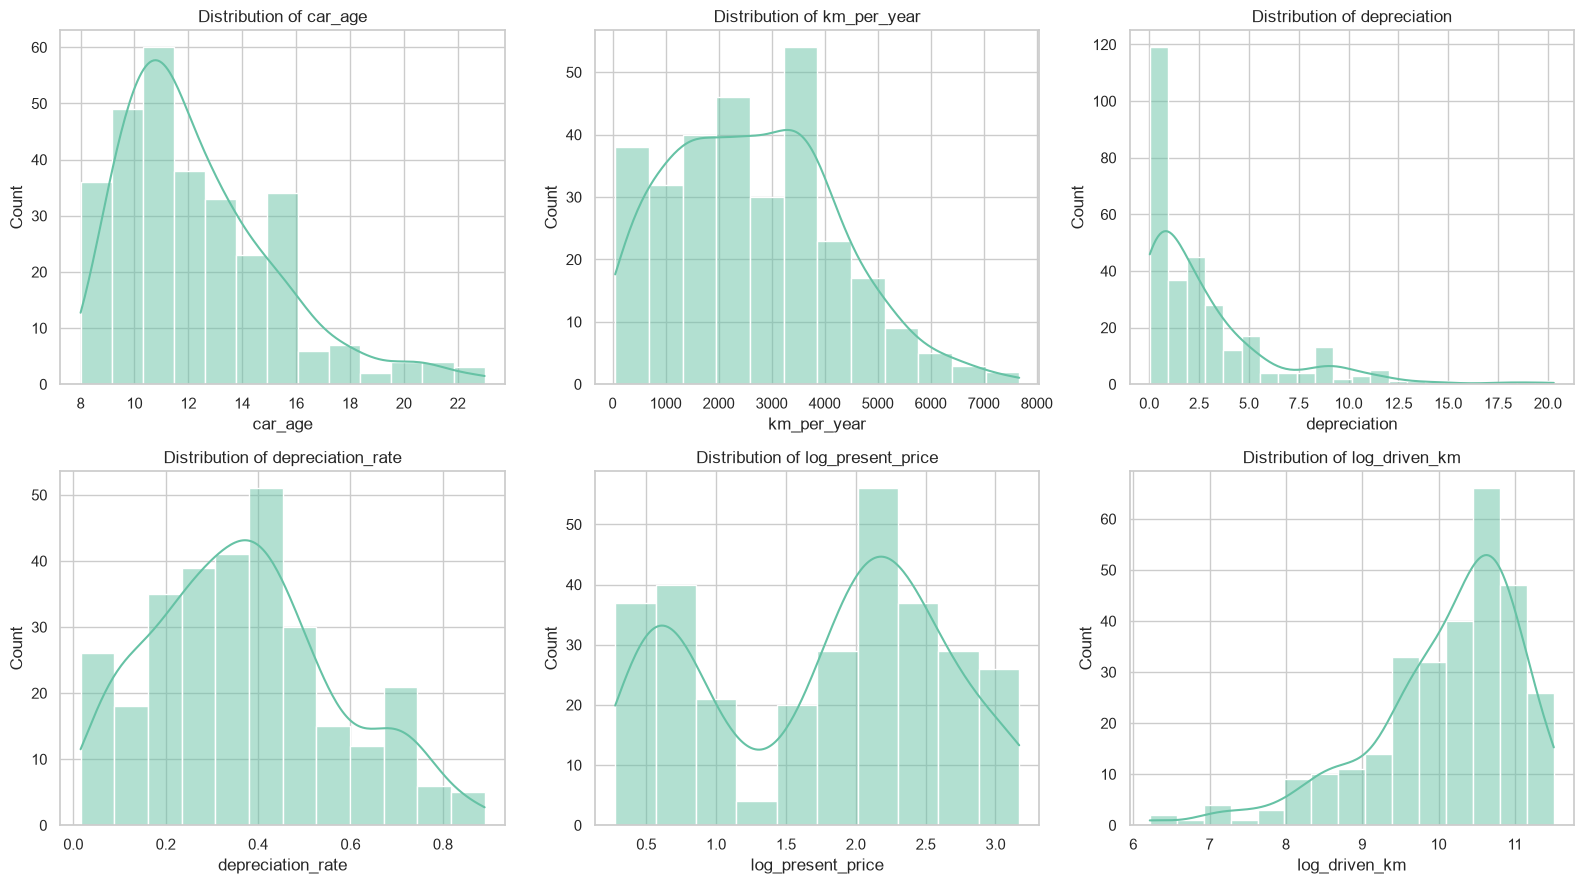

In [4]:
engineered_numeric = [
    "car_age",
    "km_per_year",
    "depreciation",
    "depreciation_rate",
    "log_present_price",
    "log_driven_km",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for axis, column in zip(axes.flatten(), engineered_numeric):
    sns.histplot(featured_data[column].dropna(), kde=True, ax=axis)
    axis.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

**Business insight:** Log features reduce right skew in price and kilometer variables. This is useful for linear models and can also stabilize downstream explanations.

## Vehicle Age and Price Segmentation

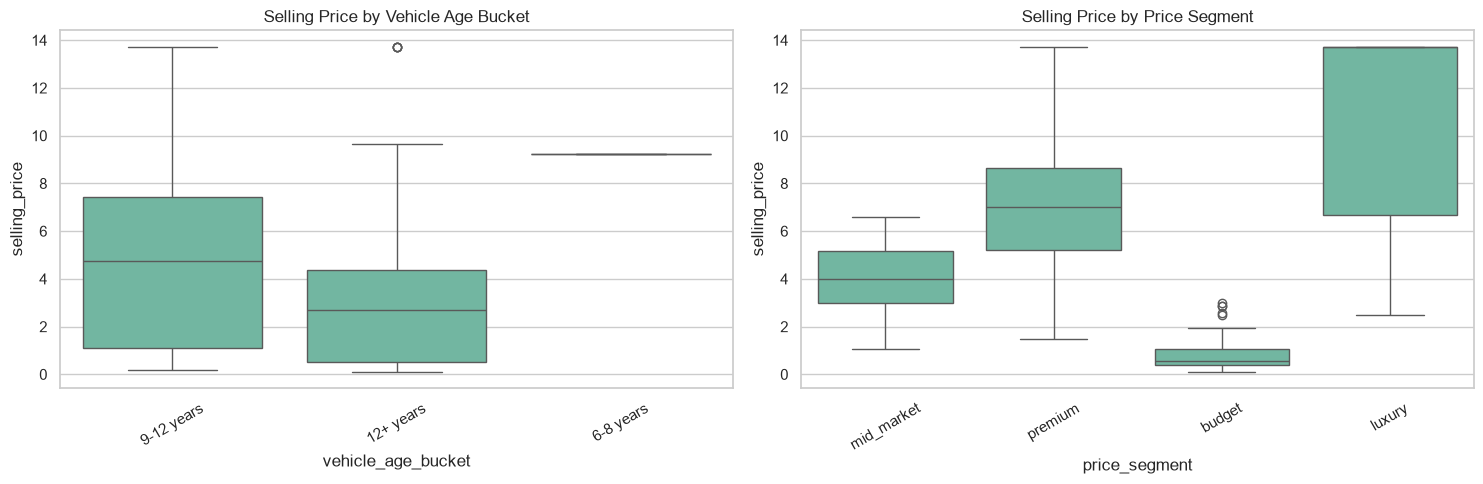

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=featured_data, x="vehicle_age_bucket", y=TARGET_COLUMN, ax=axes[0])
axes[0].set_title("Selling Price by Vehicle Age Bucket")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=featured_data, x="price_segment", y=TARGET_COLUMN, ax=axes[1])
axes[1].set_title("Selling Price by Price Segment")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

**Business insight:** Vehicle age buckets and price segments make nonlinear pricing behavior easier to capture and easier to explain. A two-year-old premium vehicle behaves differently from a ten-year-old budget vehicle even at similar kilometer levels.

## Leakage-Safe Model Features

In [6]:
model_feature_columns = get_model_feature_columns(featured_data)
target_derived_columns = ["selling_price", "log_selling_price", "depreciation", "depreciation_rate"]

print("Model feature columns:")
display(pd.DataFrame({"feature": model_feature_columns}))

print("Excluded target-derived or identifier columns:")
display(pd.DataFrame({"excluded_column": target_derived_columns + ["car_name"]}))

Model feature columns:


,feature
0,year
1,present_price
2,driven_km
3,fuel_type
4,seller_type
5,transmission
6,owner
7,car_age
8,km_per_year
9,brand


Excluded target-derived or identifier columns:


,excluded_column
0,selling_price
1,log_selling_price
2,depreciation
3,depreciation_rate
4,car_name


**Business insight:** Depreciation and depreciation rate are useful for analysis because they use the actual sale price, but they must not be model inputs. Excluding target-derived features protects the model from data leakage and keeps inference realistic.

## Build Preprocessing Pipeline

In [7]:
feature_groups = identify_feature_groups(featured_data, model_feature_columns)
preprocessor = build_preprocessor(feature_groups)

print("Numerical features:")
display(feature_groups.numerical_features)

print("Categorical features:")
display(feature_groups.categorical_features)

preprocessor

Numerical features:


['year',
 'present_price',
 'driven_km',
 'owner',
 'car_age',
 'km_per_year',
 'is_luxury_brand',
 'log_present_price',
 'log_driven_km']

Categorical features:


['fuel_type',
 'seller_type',
 'transmission',
 'brand',
 'vehicle_age_bucket',
 'price_segment']

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tr

**Business insight:** Production systems need the same preprocessing at training and prediction time. `ColumnTransformer` keeps numerical scaling and categorical one-hot encoding in one fitted object, reducing training-serving skew.

## Validate Transformed Feature Matrix

In [8]:
features = featured_data[model_feature_columns]
target = featured_data[TARGET_COLUMN]

transformed_features = preprocessor.fit_transform(features, target)
transformed_feature_names = preprocessor.get_feature_names_out()

print(f"Original feature shape: {features.shape}")
print(f"Transformed feature shape: {transformed_features.shape}")
display(pd.DataFrame(transformed_features, columns=transformed_feature_names).head())

Original feature shape: (299, 15)
Transformed feature shape: (299, 67)


,year,present_price,driven_km,owner,car_age,km_per_year,is_luxury_brand,log_present_price,log_driven_km,fuel_type_Cng,fuel_type_Diesel,fuel_type_Petrol,seller_type_Dealer,seller_type_Individual,transmission_Automatic,transmission_Manual,brand_800,brand_activa,brand_alto,brand_amaze,brand_bajaj,brand_baleno,brand_brio,brand_camry,brand_ciaz,brand_city,brand_corolla,brand_creta,brand_dzire,brand_elantra,brand_eon,brand_ertiga,brand_etios,brand_fortuner,brand_grand,brand_hero,brand_honda,brand_hyosung,brand_i10,brand_i20,brand_ignis,brand_innova,brand_jazz,brand_ktm,brand_land,brand_mahindra,brand_omni,brand_ritz,brand_royal,brand_s,brand_suzuki,brand_swift,brand_sx4,brand_tvs,brand_um,brand_verna,brand_vitara,brand_wagon,brand_xcent,brand_yamaha,vehicle_age_bucket_12+ years,vehicle_age_bucket_6-8 years,vehicle_age_bucket_9-12 years,price_segment_budget,price_segment_luxury,price_segment_mid_market,price_segment_premium
0,0.132992,-0.232617,-0.310643,-0.175101,-0.132992,-0.251964,0.0,0.158178,0.104011,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.212787,0.416991,0.362190,-0.175101,0.212787,0.422821,0.0,0.700433,0.575330,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.170329,0.467973,-1.155889,-0.175101,-1.170329,-1.198299,0.0,0.733904,-1.277697,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.904345,-0.469436,-1.227378,-0.175101,0.904345,-1.466250,0.0,-0.126511,-1.564140,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.132992,-0.022111,0.339062,-0.175101,-0.132992,0.569433,0.0,0.363135,0.562292,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


**Business insight:** One-hot encoding expands categorical variables into machine-readable signals while `handle_unknown='ignore'` allows the deployed model to receive new categories without crashing.

## Save Processed Dataset

In [9]:
processed_data = create_processed_dataset()
print(f"Saved processed dataset to: {PROCESSED_DATA_PATH}")
display(processed_data.head())

Saved processed dataset to: C:\files\Desktop\code\car_price prediction\used-car-price-prediction\data\processed\car_data_processed.csv


,car_name,year,selling_price,present_price,driven_km,fuel_type,seller_type,transmission,owner,car_age,km_per_year,brand,is_luxury_brand,vehicle_age_bucket,price_segment,log_present_price,log_driven_km,log_selling_price,depreciation,depreciation_rate
0,Ritz,2014,3.35,5.59,27000.0,Petrol,Dealer,Manual,0,12,2250.000000,ritz,0,9-12 years,mid_market,1.885553,10.203629,1.470176,2.24,0.400716
1,Sx4,2013,4.75,9.54,43000.0,Diesel,Dealer,Manual,0,13,3307.692308,sx4,0,12+ years,premium,2.355178,10.668979,1.749200,4.79,0.502096
2,Ciaz,2017,7.25,9.85,6900.0,Petrol,Dealer,Manual,0,9,766.666667,ciaz,0,9-12 years,premium,2.384165,8.839422,2.110213,2.60,0.263959
3,Wagon R,2011,2.85,4.15,5200.0,Petrol,Dealer,Manual,0,15,346.666667,wagon,0,12+ years,mid_market,1.638997,8.556606,1.348073,1.30,0.313253
4,Swift,2014,4.60,6.87,42450.0,Diesel,Dealer,Manual,0,12,3537.500000,swift,0,9-12 years,mid_market,2.063058,10.656106,1.722767,2.27,0.330422


## Feature Engineering Takeaways

- The feature set combines raw listing inputs with business-driven derived variables.
- Target-derived analysis features are intentionally separated from model inputs.
- The preprocessing pipeline uses median imputation, standard scaling, most-frequent categorical imputation, and one-hot encoding.
- The saved processed dataset supports downstream EDA, modeling, and documentation.
- The same feature engineering functions are reused by notebooks, training, API prediction, and Streamlit.